# Introduction

Combustion processes play an important role in transportation, power generation, and aerospace systems. Understanding how flames ignite, sustain combustion, and extinguish under different environmental conditions can improve the design of safer and more efficient energy technologies.

On Earth, combustion is strongly influenced by gravity\-driven buoyancy and convection. In microgravity environments, these effects are greatly reduced, allowing researchers to observe combustion phenomena that are difficult or impossible to study under normal gravitational conditions.

This project analyzes experimental data from NASA's Advanced Combustion via Microgravity Experiments (ACME) Cool Flames Investigation with Gases (CFI\-G). The objective is to investigate the behavior of spherical diffusion flames under microgravity conditions and compare normal and inverse flame configurations using publicly available NASA experimental data.

The analysis focuses on ignition behavior, flame sustainability, adiabatic flame temperature, oxygen concentration, pressure effects, and flame\-termination outcomes. Particular attention is given to identifying differences between normal and inverse diffusion flames while acknowledging the influence of experimental conditions such as fuel composition, oxygen concentration, pressure, and flow rates.



# NASA PSI\-159 Background

This study utilizes data from NASA PSI\-159: Advanced Combustion via Microgravity Experiments / Cool Flames Investigation with Gases (ACME CFI\-G).

The ACME program was conducted aboard the International Space Station (ISS) to improve scientific understanding of combustion processes in microgravity. According to NASA, the CFI\-G investigation aimed to determine the conditions under which cool diffusion flames occur for multiple gaseous fuels while examining the effects of pressure, reactant dilution, and flow conditions in both normal and inverse flame configurations.

The experimental setup employed spherical diffusion flames. In a normal flame configuration, fuel is supplied through the spherical burner into the surrounding oxidizer. In an inverse flame configuration, oxidizer is supplied through the burner into the surrounding fuel mixture.

Microgravity conditions on the ISS significantly reduce buoyancy\-driven flow, allowing combustion researchers to isolate chemical and diffusive transport processes that are often masked by gravity effects on Earth.

The PSI\-159 dataset contains experimental observations related to ignition behavior, flame extinction, combustion duration, oxygen concentration, pressure, fuel composition, burner temperature, and adiabatic flame temperature. These measurements provide an opportunity to investigate how flame configuration and operating conditions influence combustion behavior in space environments.



# Dataset Description

Two experimental datasets obtained from the NASA PSI\-159 repository were analyzed in this project:

1. Normal Flame Experimental Dataset
2. Inverse Flame Experimental Dataset

The inverse\-flame dataset initially contained 1,015 rows and 20 variables. Inspection revealed that 861 rows were completely empty and contained no experimental observations. After removal of these empty records, 154 usable inverse\-flame observations remained.

The normal\-flame dataset contained 179 experimental observations and 18 variables. No completely empty rows were present, and all records were retained for analysis.

The datasets include variables describing:

- Fuel composition
- Oxygen concentration
- Pressure
- Fuel burn rate
- Oxygen flow rate
- Ignition outcome
- Flame\-termination outcome
- Burn duration
- Adiabatic flame temperature (Tad)
- Burner temperature
- Experimental comments and observations

Three primary ignition outcomes were observed:

- Successful ignition (Yes)
- Failed ignition (No)
- Flash ignition (inverse dataset only)

Flame\-termination outcomes include:

- SE (Self\-Extinction)
- FT (Flow Termination)
- "\-" (No termination event recorded because sustained flame formation did not occur)

No missing values were artificially imputed during the cleaning process. Potentially meaningful experimental outcomes, including failed ignitions, flash events, and special termination categories, were retained to preserve scientific validity.



# Research Questions

This project seeks to answer the following questions:

1. Do normal and inverse diffusion flames exhibit different ignition behavior under microgravity conditions?
2. How do burn durations differ between normal and inverse flame configurations?
3. Does oxygen concentration influence ignition success and flame sustainability?
4. How does pressure affect combustion behavior?
5. What relationship exists between adiabatic flame temperature and flame sustainability?
6. Under comparable fuel conditions, how do normal and inverse flames differ in terms of burn duration and theoretical flame temperature?
7. What experimental conditions appear to promote stable combustion in microgravity environments?


# Exploratory Data Analysis (EDA)

In [47]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import pandas as pd

In [3]:
normal = pd.read_csv('/content/drive/MyDrive/THE_MOON/data/processed/normal_analysis.csv')
inverse = pd.read_csv('/content/drive/MyDrive/THE_MOON/data/processed/inverse_analysis.csv')

In [4]:
combined = pd.concat(
    [normal.assign(dataset='Normal'), inverse.assign(dataset='Inverse')],
    ignore_index=True
)

pd.crosstab(
    combined['dataset'],
    combined['Hot ignition'],
    normalize='index'
).round(3) * 100


Hot ignition,No,Yes,flash,no,yes
dataset,,,,,
Inverse,0.0,0.0,5.2,9.7,85.1
Normal,26.3,73.7,0.0,0.0,0.0


## Ignition Outcomes

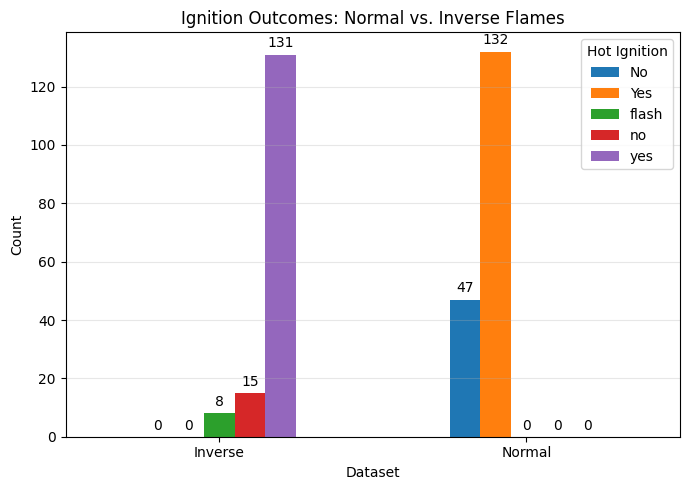

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt


combined = pd.concat(
    [normal.assign(dataset='Normal'), inverse.assign(dataset='Inverse')],
    ignore_index=True
)


ignition = pd.crosstab(
    combined['dataset'],
    combined['Hot ignition']
)

ax = ignition.plot(kind='bar', figsize=(7, 5), rot=0)

plt.title('Ignition Outcomes: Normal vs. Inverse Flames')
plt.xlabel('Dataset')
plt.ylabel('Count')
plt.legend(title='Hot Ignition')
plt.grid(axis='y', alpha=0.3)

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.tight_layout()
plt.show()


## Flame Termination Outcomes

In [7]:
combined = pd.concat(
    [normal.assign(dataset='Normal'), inverse.assign(dataset='Inverse')],
    ignore_index=True
)

termination = pd.crosstab(
    combined['dataset'],
    combined['Self -ext or flow term'],
    margins=True
)

print(termination)


Self -ext or flow term   -  ft  se  All
dataset                                
Inverse                 15  58  81  154
All                     15  58  81  154


In [8]:
normal.columns = normal.columns.str.strip()
inverse.columns = inverse.columns.str.strip()
print(normal.columns)
print(inverse.columns)

Index(['Flame Type', 'Day', 'Fuel', 'Test', 'Cool flame?', 'XO2 before test',
       'XO2  after test', 'approx p (bar)', 'Xf', 'mHC (mg/s)', 'TFP',
       'Tad (K)', 'Zst', 'Hot ignition', 'burn time (sec)',
       'Self-ext or flow term', 'Peak burner T (C )', 'Comments'],
      dtype='object')
Index(['Flame Type', 'Day', 'Fuel', 'Test', 'Xf  before test',
       'Xf  after test', 'approx p (bar)', 'XO2', 'HC burnrate (mg/s)',
       'O2 flow rate (mg/s)', 'TFP', 'Tad (K)', 'Zst', 'Hot ignition',
       'burn time (sec)', 'Self -ext or flow term', 'Peak burner Temp (C)',
       'Peak burner temp (K)', 'Color', 'Comments', 'Experiment ID',
       'Test_group'],
      dtype='object')


## Burn Time Analysis

In [9]:
comparison = pd.DataFrame({
    'Normal': normal['burn time (sec)'].describe(),
    'Inverse': inverse['burn time (sec)'].describe()
})

comparison


,Normal,Inverse
count,175.000000,154.000000
mean,44.045714,28.987013
std,64.088823,31.265934
min,0.000000,0.000000
25%,1.000000,5.000000
50%,20.000000,15.000000
75%,52.500000,62.250000
max,304.000000,152.000000


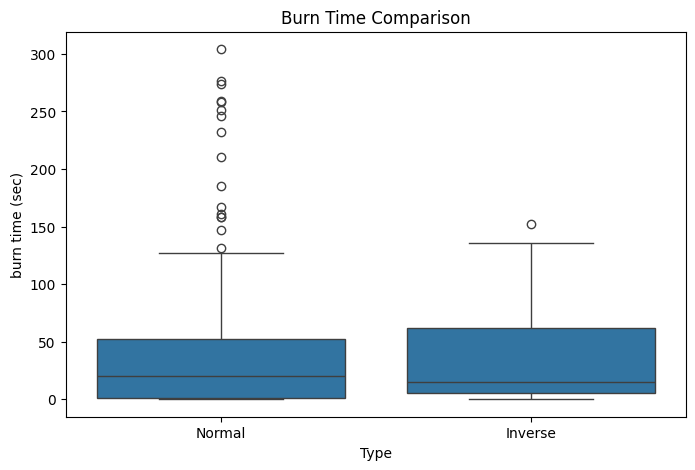

In [10]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=pd.concat([
        normal.assign(Type='Normal'),
        inverse.assign(Type='Inverse')
    ],ignore_index=True),
    x='Type',
    y='burn time (sec)'
)

plt.title('Burn Time Comparison')
plt.show()

## Adiabatic Flame Temperature (Tad)

In [11]:
normal['Tad (K)'] = pd.to_numeric(
    normal['Tad (K)'],
    errors='coerce'
)

inverse['Tad (K)'] = pd.to_numeric(
    inverse['Tad (K)'],
    errors='coerce'
)

normal['Tad (K)'].describe()
inverse['Tad (K)'].describe()

,Tad (K)
count,154.000000
mean,2407.896862
std,341.920229
min,1567.030825
25%,2204.298383
50%,2492.967081
75%,2612.785432
max,2978.371796


In [12]:
comparison_tad = pd.DataFrame({
    'Normal': normal['Tad (K)'].describe(),
    'Inverse': inverse['Tad (K)'].describe()
})

comparison_tad

,Normal,Inverse
count,177.000000,154.000000
mean,2315.489297,2407.896862
std,390.952272,341.920229
min,1397.031071,1567.030825
25%,2113.851649,2204.298383
50%,2512.315217,2492.967081
75%,2640.319200,2612.785432
max,2729.986983,2978.371796


In [13]:
normal_shared = normal[
    normal['Fuel'].str.lower().isin(
        ['ethane','propane']
    )
]

inverse_shared = inverse[
    inverse['Fuel'].str.lower().isin(
        ['ethane','propane']
    )
]

In [14]:
normal_shared.groupby('Fuel')['burn time (sec)'].describe()

,count,mean,std,min,25%,50%,75%,max
Fuel,,,,,,,,
ethane,14.0,44.785714,34.652514,7.0,16.75,42.0,58.25,127.0
propane,20.0,37.850000,68.138616,0.0,0.00,10.5,32.50,259.0


In [15]:
inverse_shared.groupby('Fuel')['burn time (sec)'].describe()

,count,mean,std,min,25%,50%,75%,max
Fuel,,,,,,,,
ethane,53.0,34.349057,30.071963,0.0,3.5,26.0,66.0,136.0
propane,43.0,25.558140,34.412278,0.0,6.5,12.0,19.5,152.0


In [16]:
normal_shared.groupby('Fuel')['Tad (K)'].describe()

,count,mean,std,min,25%,50%,75%,max
Fuel,,,,,,,,
ethane,14.0,2503.375881,249.594439,2039.856766,2319.102260,2625.112018,2702.738850,2719.323211
propane,20.0,2532.515691,217.546852,2270.589322,2274.156851,2686.828847,2704.890027,2729.986983


In [17]:
inverse_shared.groupby('Fuel')['Tad (K)'].describe()

,count,mean,std,min,25%,50%,75%,max
Fuel,,,,,,,,
ethane,53.0,2270.631720,352.696810,1567.030825,2035.764382,2397.909121,2560.723976,2820.983248
propane,43.0,2419.016361,306.511469,1834.524346,2207.969786,2506.980822,2585.681411,2978.371796


In [18]:
compare = pd.concat([
    normal_shared.assign(Type='Normal'),
    inverse_shared.assign(Type='Inverse')
])

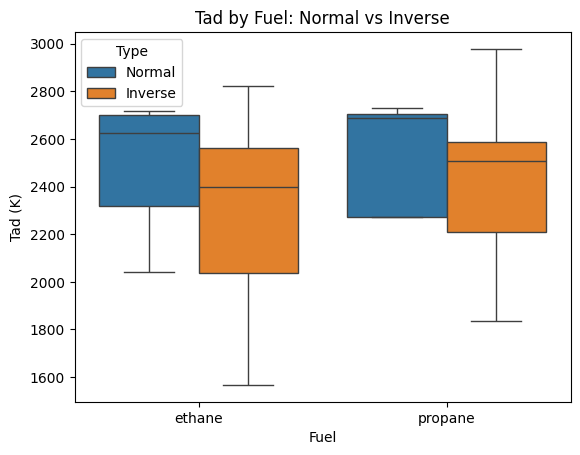

In [19]:
sns.boxplot(
    data=compare,
    x='Fuel',
    y='Tad (K)',
    hue='Type'
)

plt.title('Tad by Fuel: Normal vs Inverse')
plt.show()

## Oxygen Concentration Analysis

<Axes: xlabel='XO2 before test', ylabel='burn time (sec)'>

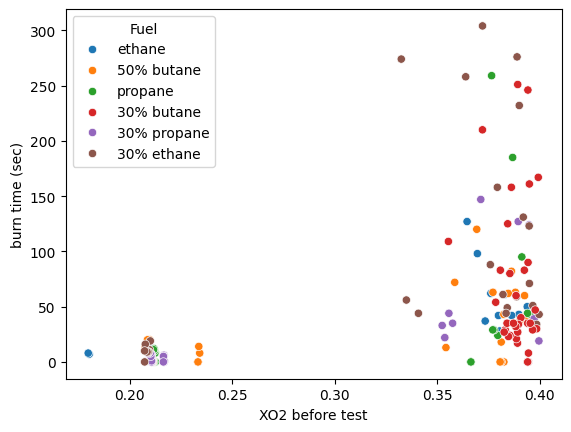

In [20]:
sns.scatterplot(
    data=normal,
    x='XO2 before test',
    y='burn time (sec)',
    hue='Fuel'
)

In [21]:
ignition_rate_normal = (
    (normal['Hot ignition'].str.lower()=='yes').mean()*100
)

ignition_rate_inverse = (
    (inverse['Hot ignition'].str.lower()=='yes').mean()*100
)

In [22]:
pd.crosstab(
    combined['dataset'],
    combined['Self-ext or flow term']
    
)

Self-ext or flow term,-,FT,SE
dataset,,,
Normal,46,31,102


<Axes: xlabel='Hot ignition', ylabel='XO2  after test'>

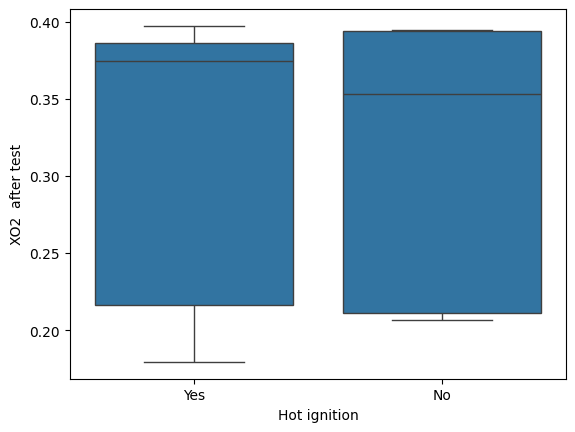

In [23]:
sns.boxplot(
    data=normal,
    x='Hot ignition',
    y='XO2  after test'
)

<Axes: xlabel='Hot ignition', ylabel='XO2'>

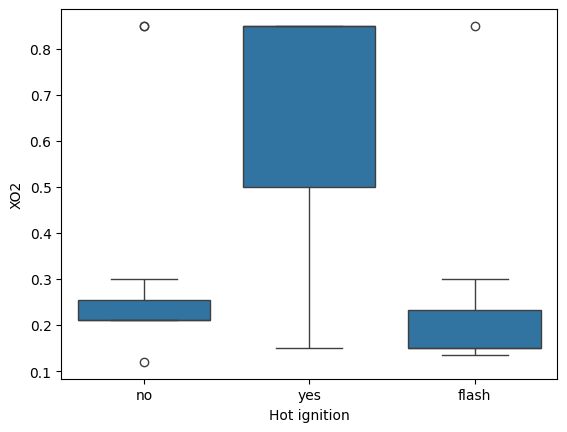

In [24]:
sns.boxplot(
    data=inverse,
    x='Hot ignition',
    y='XO2'
)

In [25]:
pd.crosstab(
    normal['Fuel'],
    normal['Hot ignition'],
    normalize='index'
)*100

Hot ignition,No,Yes
Fuel,,
30% butane,34.615385,65.384615
30% ethane,3.703704,96.296296
30% propane,25.000000,75.000000
50% butane,40.000000,60.000000
ethane,0.000000,100.000000
propane,35.000000,65.000000


In [26]:
pd.crosstab(
    normal['Fuel'],
    normal['Self-ext or flow term']
)

Self-ext or flow term,-,FT,SE
Fuel,,,
30% butane,18,9,25
30% ethane,1,5,21
30% propane,9,2,25
50% butane,11,6,13
ethane,0,5,9
propane,7,4,9


## Pressure Analysis

<Axes: xlabel='approx p (bar)', ylabel='burn time (sec)'>

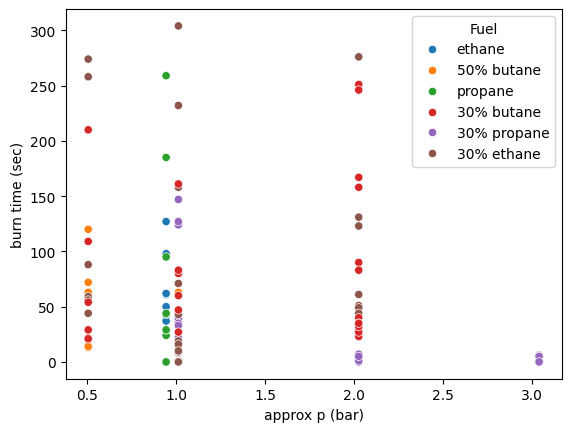

In [29]:
sns.scatterplot(
    data=normal,
    x='approx p (bar)',
    y='burn time (sec)',
    hue='Fuel'
)

<Axes: xlabel='Tad (K)', ylabel='burn time (sec)'>

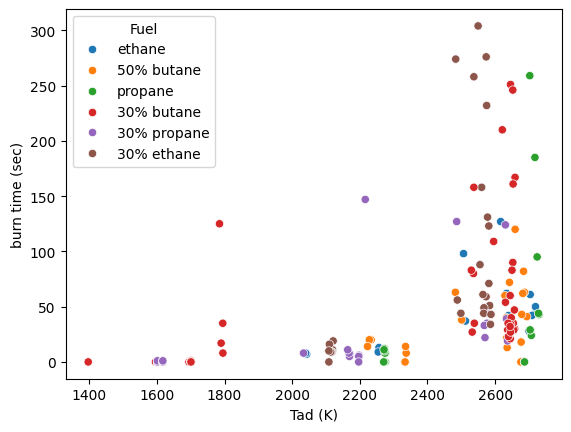

In [30]:
sns.scatterplot(
    data=normal,
    x='Tad (K)',
    y='burn time (sec)',
    hue='Fuel'
)

# Shared-Fuel Analysis

In [31]:
normal_shared = normal[
    normal['Fuel'].str.lower().isin(['ethane','propane'])
]

inverse_shared = inverse[
    inverse['Fuel'].str.lower().isin(['ethane','propane'])
]

In [32]:
normal_shared['Fuel'].value_counts()

inverse_shared['Fuel'].value_counts()

,count
Fuel,
ethane,53
propane,43


In [33]:
normal_shared.groupby('Fuel').agg(
    Burn_Time_Mean=('burn time (sec)','mean'),
    Burn_Time_Median=('burn time (sec)','median'),
    Tad_Mean=('Tad (K)','mean')
)

,Burn_Time_Mean,Burn_Time_Median,Tad_Mean
Fuel,,,
ethane,44.785714,42.0,2503.375881
propane,37.850000,10.5,2532.515691


In [34]:
inverse_shared.groupby('Fuel').agg(
    Burn_Time_Mean=('burn time (sec)','mean'),
    Burn_Time_Median=('burn time (sec)','median'),
    Tad_Mean=('Tad (K)','mean')
)

,Burn_Time_Mean,Burn_Time_Median,Tad_Mean
Fuel,,,
ethane,34.349057,26.0,2270.631720
propane,25.558140,12.0,2419.016361


In [44]:
normal_summary = normal_shared.groupby('Fuel').agg(
    Burn_Time=('burn time (sec)','mean'),
    Tad=('Tad (K)','mean')
).reset_index()

normal_summary['Flame_Type'] = 'Normal'

inverse_summary = inverse_shared.groupby('Fuel').agg(
    Burn_Time=('burn time (sec)','mean'),
    Tad=('Tad (K)','mean')
).reset_index()

inverse_summary['Flame_Type'] = 'Inverse'

shared_results = pd.concat(
    [normal_summary, inverse_summary],
    ignore_index=True
)

display(shared_results)

,Fuel,Burn_Time,Tad,Flame_Type
0,ethane,44.785714,2503.375881,Normal
1,propane,37.850000,2532.515691,Normal
2,ethane,34.349057,2270.631720,Inverse
3,propane,25.558140,2419.016361,Inverse


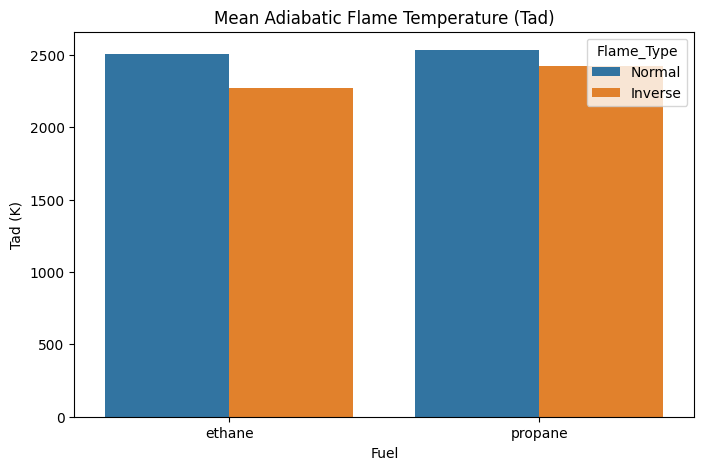

In [45]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=shared_results,
    x='Fuel',
    y='Tad',
    hue='Flame_Type'
)

plt.title('Mean Adiabatic Flame Temperature (Tad)')
plt.ylabel('Tad (K)')
plt.show()

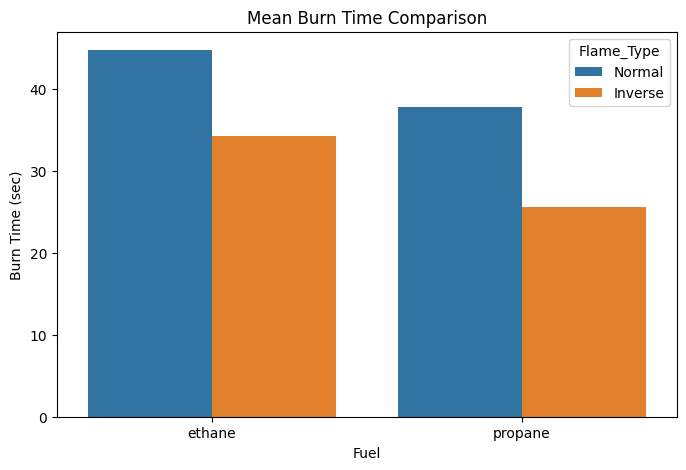

In [46]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=shared_results,
    x='Fuel',
    y='Burn_Time',
    hue='Flame_Type'
)

plt.title('Mean Burn Time Comparison')
plt.ylabel('Burn Time (sec)')
plt.show()

# Key Findings

### Data Quality and Cleaning

The inverse\-flame dataset initially contained 1,015 rows, of which 861 were completely empty and removed. This resulted in 154 valid inverse\-flame observations. The normal\-flame dataset contained 179 observations and required no row removal.

Special categories such as "\-", "Flash", and cool\-flame annotations were preserved because they represent meaningful experimental outcomes rather than data\-entry errors.

### Ignition Behavior

The normal dataset contained 132 successful ignition events and 47 failed ignition events. The inverse dataset contained 131 successful ignitions, 15 failed ignitions, and 8 flash events.

Inverse\-flame experiments exhibited a higher overall ignition success rate, while flash ignition events were observed only in inverse\-flame experiments.

### Flame Termination

Three termination outcomes were identified:

- SE (Self\-Extinction)
- FT (Flow Termination)
- "\-" (No sustained flame formed)

Analysis of records containing "\-" showed that these observations were strongly associated with failed ignition and zero burn time, indicating that they represent meaningful physical boundary conditions.

### Burn\-Time Behavior

Burn times varied substantially across both datasets, ranging from immediate extinction to more than 300 seconds.

Among the normal\-flame experiments, 30% ethane exhibited the highest average burn duration, while 30% propane exhibited the lowest.

The burn\-time distributions revealed substantial variability, indicating that flame sustainability is influenced by multiple interacting variables rather than by a single controlling factor.

### Adiabatic Flame Temperature

Adiabatic flame temperature (Tad) varied significantly among fuels and experimental conditions.

Higher Tad values were frequently associated with longer burn durations. Experiments with the longest sustained combustion generally occurred within the higher\-temperature regions of the dataset.

### Pressure Effects

Pressure ranged from approximately 0.5 to 3.0 bar. Long\-duration and short\-duration flames were observed at similar pressures, suggesting that pressure alone does not explain differences in flame sustainability.

### Oxygen Concentration Effects

Oxygen concentrations ranged from approximately 18% to 40%.

Higher oxygen concentrations were commonly associated with longer burn durations and higher adiabatic flame temperatures. However, ignition success and failure were both observed across overlapping oxygen ranges, indicating that oxygen concentration alone cannot completely explain combustion behavior.

### Shared\-Fuel Comparison

To minimize bias caused by differing fuel compositions between datasets, a comparison was performed using the shared fuels ethane and propane.

For both fuels:

- Normal flames exhibited higher average adiabatic flame temperatures than inverse flames.
- Normal flames exhibited longer average burn durations than inverse flames.

The largest difference was observed for ethane, where normal\-flame experiments exhibited both substantially higher Tad values and longer combustion durations.



# Scientific Conclusions

This study analyzed NASA PSI\-159 experimental data to investigate combustion behavior in microgravity environments and compare normal and inverse spherical diffusion flames.

The results demonstrate that combustion behavior in microgravity depends on a complex interaction among fuel composition, oxygen concentration, pressure, flame configuration, and thermal conditions.

Several important conclusions emerged from the analysis.

First, ignition success differed between flame configurations. Inverse\-flame experiments generally achieved successful ignition more frequently than normal\-flame experiments, while flash ignition events were observed only in the inverse\-flame dataset.

Second, flame sustainability varied considerably among experiments. Both short\-lived and long\-lived flames were observed under similar operating conditions, indicating that no single variable can fully explain combustion duration.

Third, adiabatic flame temperature was strongly associated with flame sustainability. Experiments exhibiting higher theoretical flame temperatures generally achieved longer burn durations, consistent with established combustion principles.

Fourth, pressure alone did not determine flame behavior. Significant variation in burn duration was observed at the same pressure levels, suggesting that pressure interacts with oxygen concentration, fuel composition, and flame configuration rather than acting independently.

Fifth, oxygen concentration appears to play an important role in combustion performance. Oxygen\-enriched conditions were frequently associated with higher flame temperatures and longer burn durations, although oxygen concentration alone did not fully determine ignition success.

Finally, the shared\-fuel comparison provided the most defensible comparison between normal and inverse flame configurations. For both ethane and propane, normal\-flame experiments exhibited higher average adiabatic flame temperatures and generally longer burn durations than inverse\-flame experiments under the conditions represented in the PSI\-159 dataset.

Overall, the analysis suggests that microgravity combustion behavior cannot be explained by flame configuration alone. Instead, ignition, flame sustainability, and combustion temperature emerge from the combined influence of fuel chemistry, oxygen availability, pressure conditions, and heat\-transfer processes.

These findings contribute to a better understanding of combustion processes in space environments and support NASA's broader objective of improving scientific knowledge relevant to future spacecraft systems and advanced combustion technologies.

